In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
# Load the dataset
df = pd.read_csv("../lab-eda-univariate/amz_uk_price_prediction_dataset.csv")

# Display the first 5 rows
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


# Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

## 1. Crosstab Analysis:

- Create a crosstab between the product category and the isBestSeller status.

In [4]:
df["category"].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [5]:
df["isBestSeller"].value_counts()

isBestSeller
False    2435671
True        7980
Name: count, dtype: int64

In [11]:
# Generating a crosstab for 'category' and 'isBestSeller'
crosstab_result = pd.crosstab(df["category"], df["isBestSeller"])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [13]:
crosstab_result[True]

category
3D Printers                         1
3D Printing & Scanning              2
Abrasive & Finishing Products       5
Action Cameras                      1
Adapters                            3
                                 ... 
Wind Instruments                    7
Window Treatments                   5
Women                             213
Women's Sports & Outdoor Shoes     20
eBook Readers & Accessories         0
Name: True, Length: 296, dtype: int64

In [14]:
# Calculate the total number of products in each category by adding False and True counts across each row
crosstab_result.sum(axis=1)

category
3D Printers                         248
3D Printing & Scanning             4067
Abrasive & Finishing Products       250
Action Cameras                     1697
Adapters                            254
                                  ...  
Wind Instruments                    250
Window Treatments                   239
Women                             17772
Women's Sports & Outdoor Shoes     1959
eBook Readers & Accessories         246
Length: 296, dtype: int64

In [15]:
# Calculate the proportion of best-sellers within each product category
best_seller_proportion = crosstab_result[True] / crosstab_result.sum(axis=1)

# Display the proportion for each category
best_seller_proportion

category
3D Printers                       0.004032
3D Printing & Scanning            0.000492
Abrasive & Finishing Products     0.020000
Action Cameras                    0.000589
Adapters                          0.011811
                                    ...   
Wind Instruments                  0.028000
Window Treatments                 0.020921
Women                             0.011985
Women's Sports & Outdoor Shoes    0.010209
eBook Readers & Accessories       0.000000
Length: 296, dtype: float64

In [16]:
# Sort product categories from the highest to the lowest best-seller proportion
best_seller_proportion_sorted = best_seller_proportion.sort_values(ascending=False)

# Display the 10 categories with the highest best-seller proportions
best_seller_proportion_sorted.head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Mirrors                           0.028000
Wind Instruments                  0.028000
dtype: float64

In [17]:
# Display the total number of products in the 10 categories with the highest best-seller proportions
crosstab_result.sum(axis=1).loc[best_seller_proportion_sorted.head(10).index]

category
Grocery                           9564
Smart Home Security & Lighting     104
Health & Personal Care            9569
Mobile Phone Accessories           259
Power & Hand Tools                8659
Billiard, Snooker & Pool           249
Pet Supplies                      9437
Home Brewing & Wine Making         246
Mirrors                            250
Wind Instruments                   250
dtype: int64

- Are there categories where being a best-seller is more prevalent?

Yes, some product categories have a higher proportion of best-sellers than others. Grocery has the highest proportion at approximately 5.81%, followed by Smart Home Security & Lighting at 5.77% and Health & Personal Care at 5.77%.

However, the number of products varies considerably across categories. For example, Grocery contains 9,564 products, whereas Smart Home Security & Lighting contains only 104. Therefore, the proportions should be interpreted alongside the number of products in each category.

## 2. Statistical Tests:

- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [18]:
from scipy.stats import chi2_contingency

In [23]:
chi2_contingency(crosstab_result)

Chi2ContingencyResult(statistic=np.float64(36540.20270061387), pvalue=np.float64(0.0), dof=295, expected_freq=array([[2.47190130e+02, 8.09870149e-01],
       [4.05371878e+03, 1.32812173e+01],
       [2.49183599e+02, 8.16401360e-01],
       [1.69145827e+03, 5.54173243e+00],
       [2.53170536e+02, 8.29463782e-01],
       [8.50214439e+03, 2.78556144e+01],
       [1.06650580e+02, 3.49419782e-01],
       [2.57157474e+02, 8.42526204e-01],
       [9.51781673e+03, 3.11832664e+01],
       [1.50008526e+04, 4.91473619e+01],
       [9.32544700e+03, 3.05530045e+01],
       [2.38219520e+02, 7.80479700e-01],
       [3.22941944e+03, 1.05805616e+01],
       [9.44704859e+03, 3.09514084e+01],
       [6.68808779e+03, 2.19122125e+01],
       [5.26275760e+02, 1.72423967e+00],
       [1.90296531e+04, 6.23469391e+01],
       [2.77191835e+03, 9.08164873e+00],
       [2.53170536e+02, 8.29463782e-01],
       [4.04674164e+02, 1.32583581e+00],
       [1.92489346e+04, 6.30653723e+01],
       [3.10482764e+03, 1.017

In [ ]:
# H0: no connection between best-seller and category--> DISCARD
# H1: connection between best-seller and category--> ACCEPT --> category and best-seller status are associated

# Test whether category and best-seller status are independent
chi2_stat, p_value, _, _ = chi2_contingency(crosstab_result)
chi2_stat, p_value

(np.float64(36540.20270061387), np.float64(0.0))

A Chi-square test of independence returned a statistic of 36,540.20 and a p-value smaller than 0.05. Therefore, we reject H0 and conclude that there is a statistically significant association between product category and best-seller status. This suggests that best-seller proportions differ across product categories, although the test does not establish causation.

- Compute Cramér's V to understand the strength of association between best-seller status and category.

In [27]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")

0.1222829439760564

Cramér's V was calculated to measure the strength of the association between product category and best-seller status. The result was approximately 0.1223, indicating a weak association.

Although the Chi-square test found a statistically significant association between the two variables, the low Cramér's V suggests that the strength of this relationship is limited. Therefore, product category is associated with best-seller status, but the association is relatively weak.

## 3. Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

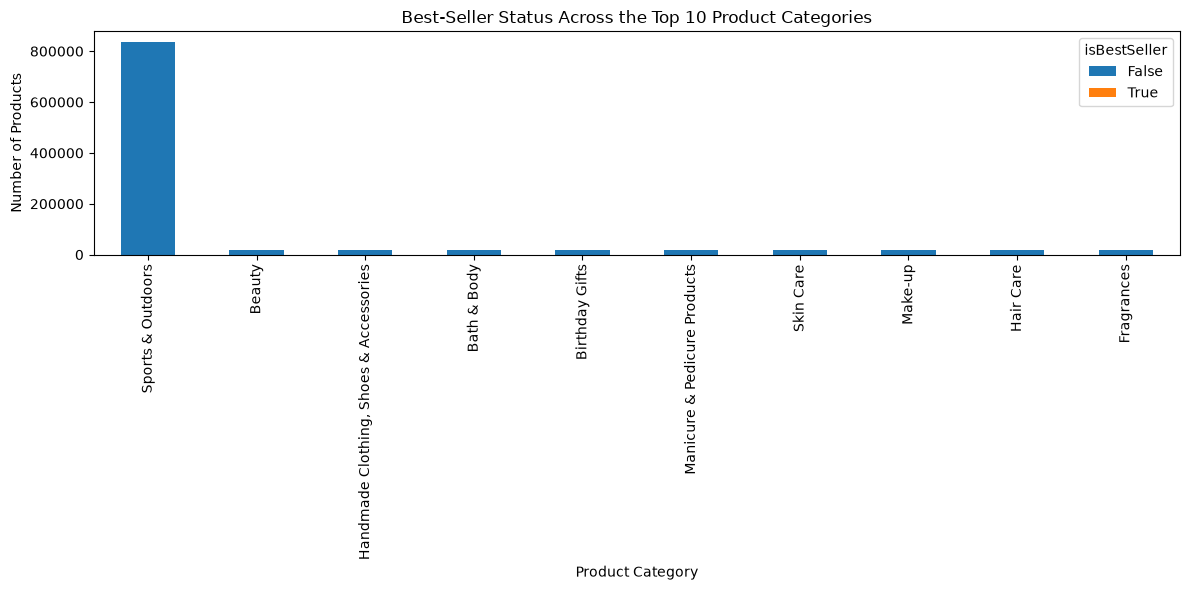

In [32]:
# Select the 10 categories with the highest total number of products
top_10_categories = crosstab_result.sum(axis=1).nlargest(10).index

# Keep only these categories in the crosstab
crosstab_top_10 = crosstab_result.loc[top_10_categories]

# Create a stacked bar chart comparing best-seller and non-best-seller counts
crosstab_top_10.plot(kind="bar", stacked=True, figsize=(12, 6))

# Add a title and axis labels to explain the chart
plt.title("Best-Seller Status Across the Top 10 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")

# Adjust the layout to prevent labels from being cut off
plt.tight_layout()

The stacked bar chart shows that Sports & Outdoors has a substantially higher number of products than the other categories displayed. However, the chart represents absolute counts, so categories with more products naturally tend to have larger bars. The number of products alone does not indicate a higher likelihood of being a best-seller.

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

## 0. Preliminary Step: Remove outliers in product prices.

- For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

In [33]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

In [34]:
# Calculate the first and third quartiles of product prices
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

# Display the quartile values
print("Q1:", Q1)
print("Q3:", Q3)

Q1: 9.99
Q3: 45.99


In [35]:
# Calculate the interquartile range (IQR)
IQR = Q3 - Q1

# Calculate the lower and upper limits for identifying price outliers
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Display the calculated limits
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

IQR: 36.0
Lower limit: -44.01
Upper limit: 99.99000000000001


In [36]:
# Keep only products with prices within the IQR limits
df_no_outliers = df[(df["price"] >= lower_limit) & (df["price"] <= upper_limit)].copy()

# Display the original and filtered dataset sizes
print("Original dataset shape:", df.shape)
print("Dataset without price outliers:", df_no_outliers.shape)

Original dataset shape: (2443651, 9)
Dataset without price outliers: (2115963, 9)


In [37]:
# Calculate how many products were removed and the percentage of the original dataset
removed_products = df.shape[0] - df_no_outliers.shape[0]
percentage_removed = (removed_products / df.shape[0]) * 100

# Display the results
print("Products removed:", removed_products)
print("Percentage removed:", round(percentage_removed, 2), "%")

Products removed: 327688
Percentage removed: 13.41 %


In [38]:
# Check for missing prices in the cleaned dataset
print("Missing prices:", df_no_outliers["price"].isna().sum())

# Display descriptive statistics for prices after removing outliers
display(df_no_outliers["price"].describe())

Missing prices: 0


count    2.115963e+06
mean     2.340827e+01
std      2.051335e+01
min      0.000000e+00
25%      9.130000e+00
50%      1.599000e+01
75%      2.999000e+01
max      9.999000e+01
Name: price, dtype: float64

## 1. Violin Plots:

- Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.

In [39]:
# Count the number of products in each category and select the 20 largest categories
top_20_categories = df_no_outliers["category"].value_counts().head(20).index

# Filter the cleaned dataframe to include only these 20 categories
df_top_20 = df_no_outliers[df_no_outliers["category"].isin(top_20_categories)].copy()

# Display the number of categories and products selected
print("Number of categories:", df_top_20["category"].nunique())
print("Number of products:", len(df_top_20))

Number of categories: 20
Number of products: 1033008


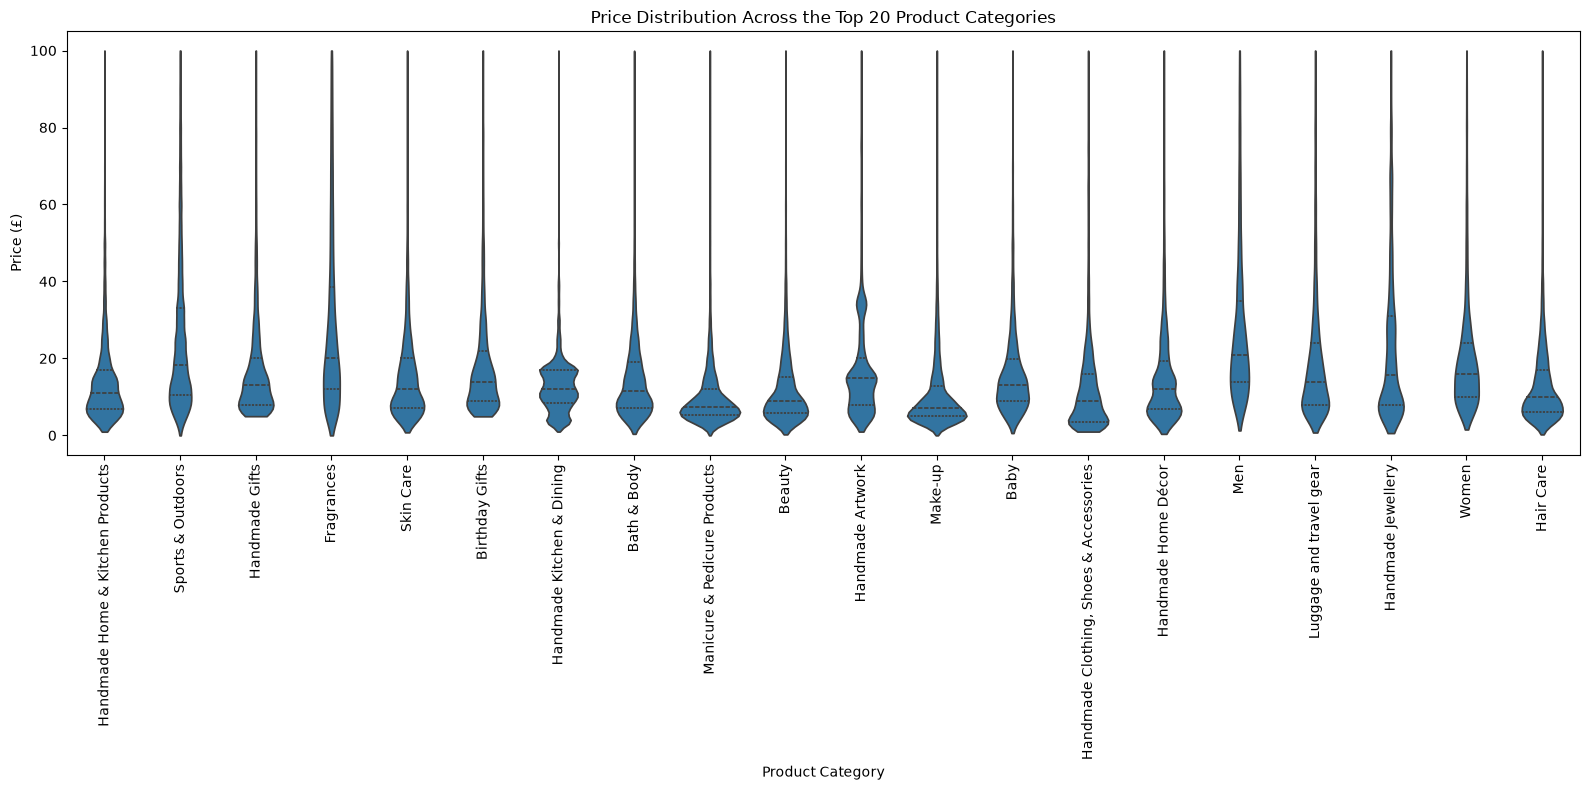

In [42]:
# Create a violin plot showing price distributions across the 20 largest categories
plt.figure(figsize=(16, 8))
sns.violinplot(data=df_top_20, x="category", y="price", inner="quartile", cut=0)

# Add a title and labels
plt.title("Price Distribution Across the Top 20 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Price (£)")

# Rotate category labels to improve readability
plt.xticks(rotation=90)

# Adjust spacing and display the plot
plt.tight_layout()

- Which product category tends to have the highest median price? Don't filter here by top categories.

In [45]:
# Calculate the median price for every category in the cleaned dataset
median_prices = df_no_outliers.groupby("category")["price"].median()

# Find the category with the highest median price
highest_median_category = median_prices.idxmax()
highest_median_price = median_prices.max()

# Display the result
print("Category with the highest median price:", highest_median_category)
print("Highest median price: £", highest_median_price)

Category with the highest median price: Desktop PCs
Highest median price: £ 74.0


Desktop PCs have the highest median price among all product categories after removing price outliers. This means the middle-priced product in this category costs £74, which is higher than the median in every other category.

## 2. Bar Charts:

- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

In [46]:
# Identify the 10 categories with the most products in the cleaned dataset
top_10_categories = df_no_outliers["category"].value_counts().head(10).index

# Keep only products belonging to these 10 categories
df_top_10 = df_no_outliers[df_no_outliers["category"].isin(top_10_categories)].copy()

In [47]:
# Calculate the average price for each of the 10 selected categories
average_prices_top_10 = (
    df_top_10.groupby("category")["price"].mean().sort_values(ascending=False)
)

# Display the average prices from highest to lowest
display(average_prices_top_10)

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

- Which product category commands the highest average price? Don't filter here by top categories.

In [52]:
# Calculate the average price for every category in the cleaned dataset
average_prices_all = df_no_outliers.groupby("category")["price"].mean()

# Identify the category with the highest average price
highest_average_category = average_prices_all.idxmax()
highest_average_price = average_prices_all.max()

# Display the result
print("Category with the highest average price:", highest_average_category)
print("Highest average price: £", round(highest_average_price, 2))

Category with the highest average price: Motherboards
Highest average price: £ 68.77


Motherboards have the highest average price across all product categories (£68.77), suggesting a higher price point than other categories. Among the 10 largest categories by product count, Sports & Outdoors has the highest average price (£25.17). This shows that the categories with the highest product volumes do not necessarily have the highest average prices.

## 2. Box Plots:

- Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

In [53]:
# Select the 10 categories with the most products in the cleaned dataset
top_10_rating_categories = df_no_outliers["category"].value_counts().head(10).index

# Filter the dataset to include only products from these categories
df_top_10_ratings = df_no_outliers[
    df_no_outliers["category"].isin(top_10_rating_categories)
].copy()

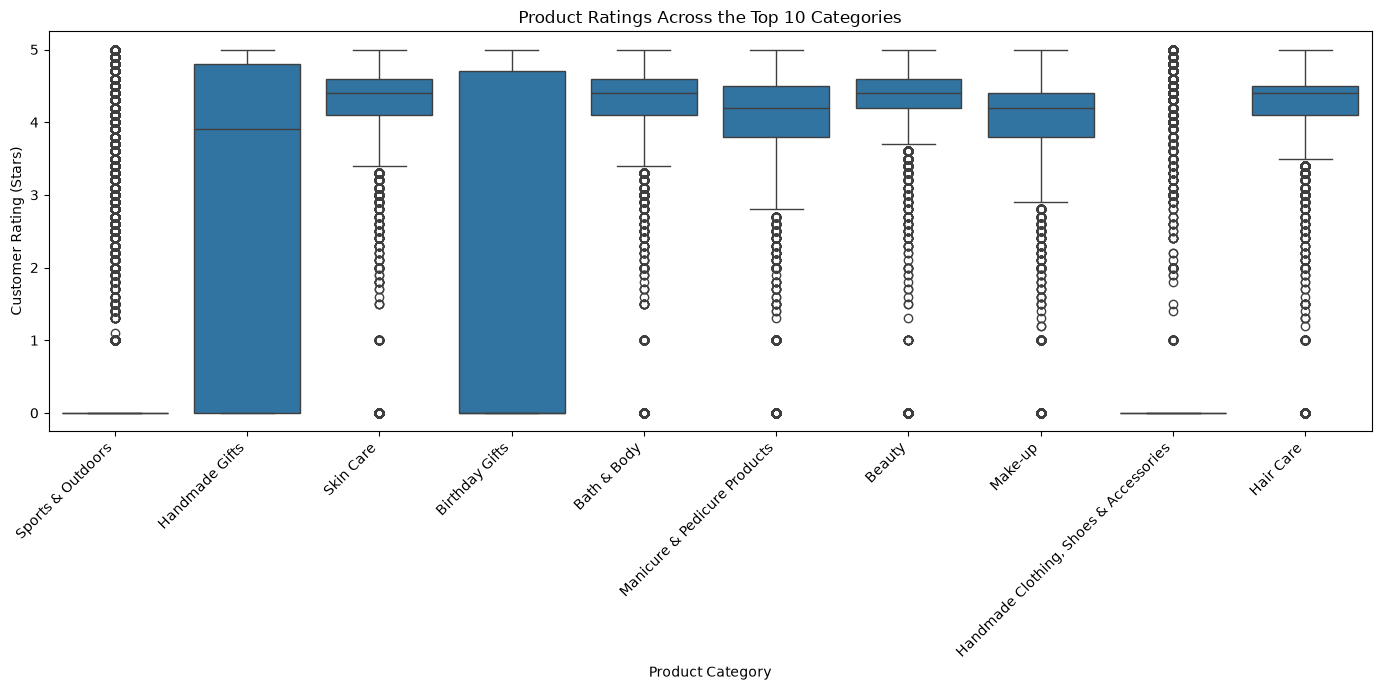

In [57]:
# Create side-by-side box plots to compare product ratings across the top 10 categories
plt.figure(figsize=(14, 7))
sns.boxplot(data=df_top_10_ratings, x="category", y="stars")

# Add a title and axis labels
plt.title("Product Ratings Across the Top 10 Categories")
plt.xlabel("Product Category")
plt.ylabel("Customer Rating (Stars)")

# Rotate category labels for readability
plt.xticks(rotation=45, ha="right")

# Adjust spacing to prevent labels from being cut off
plt.tight_layout()

- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [58]:
# Calculate the median customer rating for every category
median_ratings_all = df_no_outliers.groupby("category")["stars"].median()

# Find the category with the highest median rating
highest_median_rating_category = median_ratings_all.idxmax()
highest_median_rating = median_ratings_all.max()

# Display the result
print("Category with the highest median rating:", highest_median_rating_category)
print("Highest median rating:", highest_median_rating)

Category with the highest median rating: Computer Memory
Highest median rating: 4.7


Computer Memory has the highest median customer rating across all categories, at 4.7 out of 5 stars, indicating strong customer satisfaction compared with other product categories.

# Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

## 1. Correlation Coefficients: 

- Calculate the correlation coefficient between price and stars.

In [59]:
# Keep products with an actual rating and non-missing price values
df_price_ratings = df_no_outliers[
    (df_no_outliers["stars"] > 0) & df_no_outliers["price"].notna()
].copy()

# Calculate Pearson's correlation coefficient and its p-value
from scipy.stats import pearsonr

correlation, p_value = pearsonr(df_price_ratings["price"], df_price_ratings["stars"])

# Display the results
print("Correlation coefficient:", round(correlation, 4))
print("P-value:", p_value)

Correlation coefficient: 0.0067
P-value: 1.0813032347760899e-12


- Is there a significant correlation between product price and its rating?

- Statistically significant: Yes. The p-value is far below 0.05, so we reject the null hypothesis of no linear correlation.
- Strength of the relationship: Essentially zero. A correlation of 0.0067 indicates a negligible positive linear relationship.

## 2. Visualizations:

- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

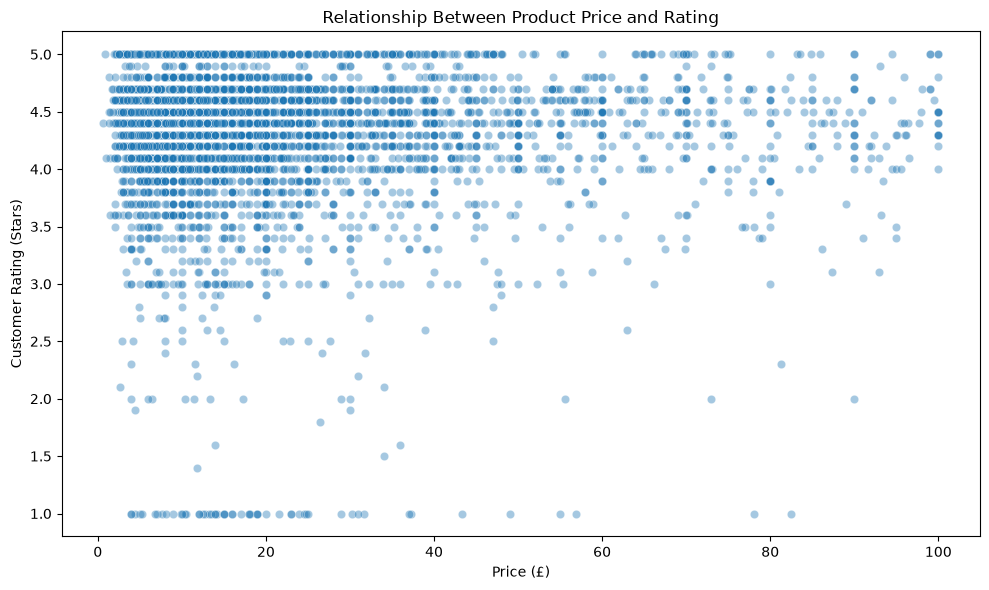

In [60]:
# Select a random sample of 5,000 rated products for a clearer scatter plot
df_scatter = df_price_ratings.sample(n=5000, random_state=42)

# Plot product price against customer rating
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_scatter, x="price", y="stars", alpha=0.4)

# Add a title and axis labels
plt.title("Relationship Between Product Price and Rating")
plt.xlabel("Price (£)")
plt.ylabel("Customer Rating (Stars)")

# Adjust spacing
plt.tight_layout()

Product ratings are generally concentrated between 3.5 and 5 stars for products priced up to around £40. However, ratings vary at similar price levels, and the correlation coefficient of 0.0067 indicates virtually no linear relationship between price and rating. Therefore, higher prices do not appear to reliably predict better customer ratings.

- Use a correlation heatmap to visualize correlations between all numerical variables.

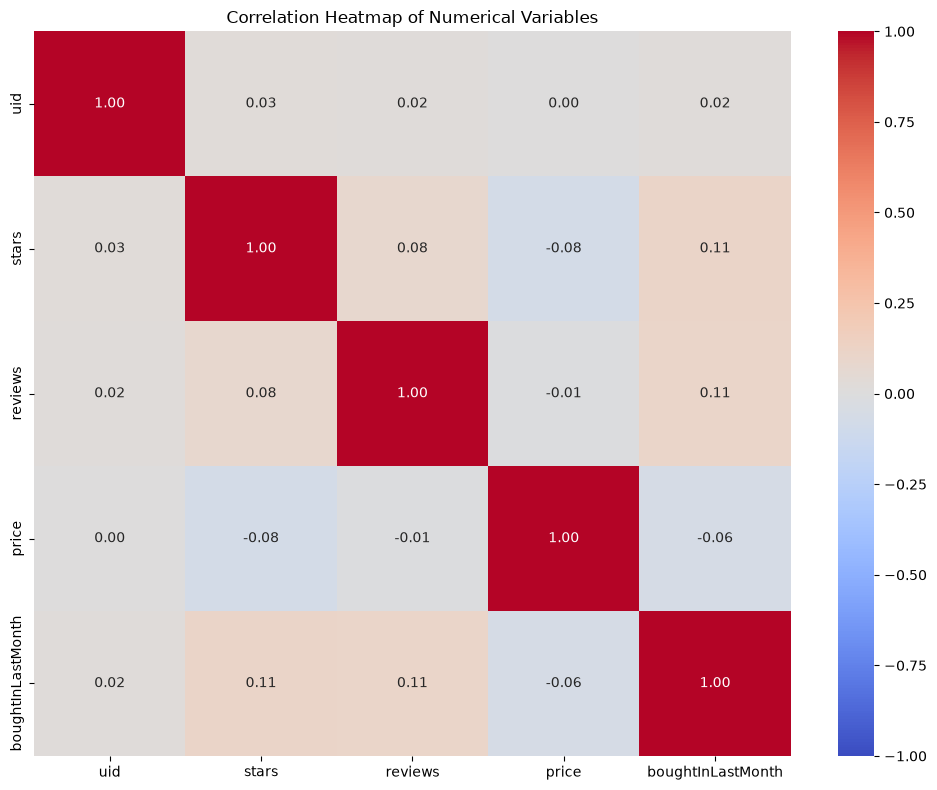

In [61]:
# Select numerical columns for the correlation analysis
numeric_df = df_no_outliers.select_dtypes(include="number")

# Calculate correlations between all numerical variables
correlation_matrix = numeric_df.corr()

# Visualize the correlation matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)

# Add a title and adjust spacing
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()

The heatmap shows the relationships between numerical variables. The correlation between price and ratings is close to zero, meaning that higher prices do not necessarily mean higher ratings.

- Examine if product prices typically follow a normal distribution using a QQ plot.

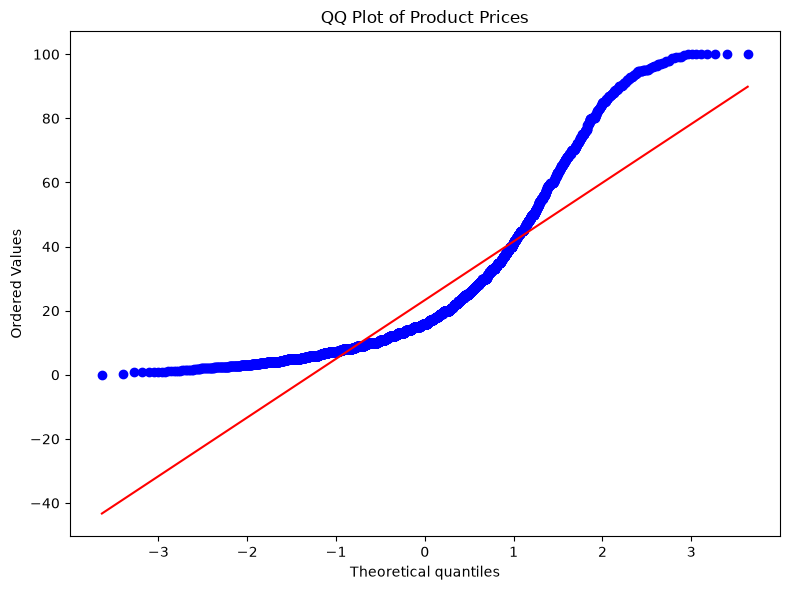

In [62]:
# Import the QQ plot function
from scipy import stats

# Draw a QQ plot using a sample of prices to keep it efficient
price_sample = (
    df_no_outliers["price"]
    .dropna()
    .sample(n=min(5000, df_no_outliers["price"].notna().sum()), random_state=42)
)

# Compare the price sample with a theoretical normal distribution
plt.figure(figsize=(8, 6))
stats.probplot(price_sample, dist="norm", plot=plt)

# Add a title and adjust spacing
plt.title("QQ Plot of Product Prices")
plt.tight_layout()

The QQ plot helps us check whether product prices follow a normal distribution. If the points deviate from the straight line, it indicates that prices are not normally distributed. In this case, prices are likely right-skewed, with many cheaper products and fewer expensive ones.